
# Lab 4 — Generative Models with PyTorch
### Auto-Encoder (AE) · Variational Auto-Encoder (VAE) · Generative Adversarial Network (GAN)

</div>

**Objective.** Get familiar with PyTorch by building deep generative architectures:

| Part | Model | Dataset |
|---|---|---|
| 1 | Auto-Encoder and Variational Auto-Encoder | MNIST |
| 2 | GAN (DCGAN) | Abstract Art Gallery (Kaggle) |



## 0. Setup
Imports, reproducibility (fixed seed), GPU configuration and output folders.

In [1]:
# Install the few extra dependencies if missing (already present on Kaggle/Colab in most cases)
import importlib, subprocess, sys
for pkg in ["kagglehub", "scipy", "scikit-learn", "pandas", "tqdm"]:
    mod = "sklearn" if pkg == "scikit-learn" else pkg
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [2]:
import os, random, json, time, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid

from sklearn.manifold import TSNE
from scipy.stats import norm

# ---------- Reproducibility ----------
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

# ---------- GPU setting ----------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__)
print("Device  :", device, "-", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (training will be slow!)")

# ---------- Output folders ----------
OUT = Path("outputs"); (OUT / "figures").mkdir(parents=True, exist_ok=True); (OUT / "models").mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=150, bbox_inches="tight")

RESULTS = {}   # every key number of the lab is collected here and exported at the end
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

PyTorch : 2.14.1+cu130
Device  : cuda - Tesla T4


---
# PART 1 — Auto-Encoder (AE) and Variational Auto-Encoder (VAE) on MNIST

## 1.1 Data
MNIST contains 70 000 grey-scale digits of size 28×28 (60 000 train / 10 000 test). The Kaggle dataset `hojjatk/mnist-dataset` is the original MNIST in IDX format, so we load the very same data through `torchvision` (automatic download; on Kaggle make sure *Internet* is enabled).

* Pixels are scaled to **[0, 1]** (`ToTensor`), which matches a `Sigmoid` output layer and a Binary Cross-Entropy reconstruction loss.
* The training set is split into **55 000 train / 5 000 validation**; the validation set is used to select the hyper-parameters, and the **test set is only used for the final evaluation**.

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 502kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.63MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.41MB/s]

train=55000  val=5000  test=10000


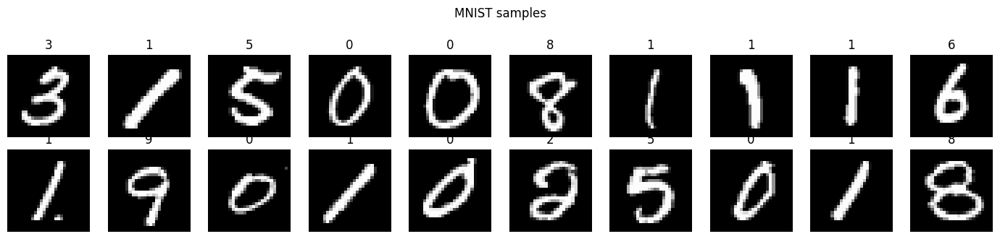

In [3]:
BATCH = 128
tfm = transforms.ToTensor()
full_train = datasets.MNIST("data", train=True,  download=True, transform=tfm)
test_set   = datasets.MNIST("data", train=False, download=True, transform=tfm)
train_set, val_set = random_split(full_train, [55000, 5000], generator=torch.Generator().manual_seed(SEED))

kw = dict(batch_size=BATCH, num_workers=2, pin_memory=(device.type == "cuda"))
train_loader = DataLoader(train_set, shuffle=True,  **kw)
val_loader   = DataLoader(val_set,   shuffle=False, **kw)
test_loader  = DataLoader(test_set,  shuffle=False, **kw)
print(f"train={len(train_set)}  val={len(val_set)}  test={len(test_set)}")

# Quick look at the data
x, y = next(iter(train_loader))
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(x[i, 0], cmap="gray"); ax.set_title(int(y[i])); ax.axis("off")
plt.suptitle("MNIST samples", y=1.02); plt.tight_layout(); savefig("p1_mnist_samples"); plt.show()

## 1.2 Auto-Encoder architecture
An auto-encoder learns a compressed representation (the *code* **z**) by reconstructing its own input:

$$x \xrightarrow{\text{Encoder } f_\phi} z \in \mathbb{R}^{d} \xrightarrow{\text{Decoder } g_\theta} \hat{x}, \qquad \mathcal{L}_{AE} = \text{BCE}(x, \hat{x})$$

* **Encoder**: `784 → 512 → 256 → d` (ReLU)
* **Decoder**: `d → 256 → 512 → 784` (ReLU, final Sigmoid)
* **Loss**: Binary Cross-Entropy summed over the 784 pixels and averaged over the batch (so that it is directly comparable with the reconstruction term of the VAE).
* **Optimiser**: Adam.

## 1.3 Variational Auto-Encoder architecture
The VAE encodes an input into a **distribution** $q_\phi(z|x)=\mathcal{N}(\mu, \sigma^2 I)$ instead of a single point, and is trained by maximising the Evidence Lower BOund (ELBO):

$$\mathcal{L}_{VAE} = \underbrace{\mathbb{E}_{q_\phi(z|x)}\big[-\log p_\theta(x|z)\big]}_{\text{reconstruction (BCE)}} \;+\; \beta\,\underbrace{D_{KL}\big(q_\phi(z|x)\,\|\,\mathcal{N}(0,I)\big)}_{\text{regularisation}}$$

with the closed form $D_{KL} = -\tfrac12\sum_j \left(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2\right)$.
Sampling is made differentiable by the **re-parameterisation trick**: $z=\mu+\sigma\odot\epsilon,\ \epsilon\sim\mathcal{N}(0,I)$. We use $\beta=1$ (standard VAE).

The VAE encoder shares the same trunk as the AE (`784 → 512 → 256`) followed by two heads (`μ` and `log σ²`), and the decoder is identical to the AE one.

In [4]:
class AE(nn.Module):
    """Fully-connected auto-encoder: 784 -> 512 -> 256 -> d -> 256 -> 512 -> 784."""
    def __init__(self, latent_dim=16):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 784), nn.Sigmoid(),
        )
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        z = self.encoder(x)
        return self.decode(z), z


class VAE(nn.Module):
    """Fully-connected VAE with the re-parameterisation trick."""
    def __init__(self, latent_dim=16):
        super().__init__()
        self.latent_dim = latent_dim
        self.trunk = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
        )
        self.fc_mu     = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 784), nn.Sigmoid(),
        )
    def encode(self, x):
        h = self.trunk(x)
        return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


BETA = 1.0
def vae_loss(x_hat, x, mu, logvar, beta=BETA):
    """Negative ELBO, averaged per image. Returns (total, reconstruction, KL)."""
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / x.size(0)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon + beta * kl, recon, kl


n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"AE  (d=16) parameters: {n_params(AE(16)):,}")
print(f"VAE (d=16) parameters: {n_params(VAE(16)):,}")

AE  (d=16) parameters: 1,075,488
VAE (d=16) parameters: 1,079,600


### Training utilities
One generic `run_epoch` / `fit` pair handles both models. For every epoch we log the total loss, the reconstruction term and the KL term (KL = 0 for the AE) on both the training and the validation sets, and we **keep the weights of the epoch with the best validation loss**.

In [5]:
def run_epoch(model, kind, loader, optimizer=None):
    """One pass over `loader`. Trains if an optimizer is given, otherwise evaluates."""
    training = optimizer is not None
    model.train(training)
    sums, n = np.zeros(3), 0                      # total, recon, kl
    with torch.set_grad_enabled(training):
        for x, _ in loader:
            x = x.to(device, non_blocking=True)
            if kind == "ae":
                x_hat, _ = model(x)
                recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / x.size(0)
                kl, loss = torch.zeros((), device=device), recon
            else:
                x_hat, mu, logvar = model(x)
                loss, recon, kl = vae_loss(x_hat, x, mu, logvar)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            b = x.size(0)
            sums += np.array([loss.item(), recon.item(), kl.item()]) * b
            n += b
    s = sums / n
    return dict(total=s[0], recon=s[1], kl=s[2])


def fit(kind, latent_dim, lr, epochs, verbose=True):
    """Train an AE ('ae') or VAE ('vae'); returns the best-validation model and the training history."""
    set_seed()
    model = (AE if kind == "ae" else VAE)(latent_dim).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {f"{s}_{k}": [] for s in ("train", "val") for k in ("total", "recon", "kl")}
    best_val, best_state, best_ep = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        tr = run_epoch(model, kind, train_loader, opt)
        va = run_epoch(model, kind, val_loader)
        for k in tr:
            hist[f"train_{k}"].append(tr[k]); hist[f"val_{k}"].append(va[k])
        if va["total"] < best_val:
            best_val, best_ep = va["total"], ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose and (ep == 1 or ep % 5 == 0 or ep == epochs):
            print(f"[{kind.upper()} d={latent_dim} lr={lr:g}] epoch {ep:3d}/{epochs} | "
                  f"train {tr['total']:.2f} | val {va['total']:.2f}" + (f" (recon {va['recon']:.2f}, KL {va['kl']:.2f})" if kind == "vae" else ""))
    model.load_state_dict(best_state)
    hist["best_epoch"], hist["best_val"] = best_ep, best_val
    return model, hist

## 1.4 Hyper-parameter selection
The two hyper-parameters with the largest impact are the **latent dimension** $d$ (capacity of the bottleneck) and the **learning rate**. We run a small grid search (short training of 5 epochs per configuration) and select the configuration with the lowest **validation** loss. The batch size (128) and the optimiser (Adam) are kept fixed.

For the AE the criterion is the validation reconstruction BCE; for the VAE it is the validation negative ELBO (reconstruction + KL).

In [6]:
LATENT_GRID = [8, 16, 32]
LR_GRID     = [1e-3, 3e-4]
SEARCH_EPOCHS = 5

def grid_search(kind):
    rows = []
    for d in LATENT_GRID:
        for lr in LR_GRID:
            _, h = fit(kind, d, lr, SEARCH_EPOCHS, verbose=False)
            b = h["best_epoch"] - 1
            rows.append(dict(latent_dim=d, lr=lr, val_total=h["val_total"][b], val_recon=h["val_recon"][b], val_kl=h["val_kl"][b]))
            print(f"{kind.upper()}  d={d:<3} lr={lr:<7g} -> val loss {rows[-1]['val_total']:.2f}")
    return pd.DataFrame(rows).sort_values("val_total").reset_index(drop=True)

t0 = time.time()
ae_grid  = grid_search("ae")
vae_grid = grid_search("vae")
print(f"\nGrid search done in {(time.time()-t0)/60:.1f} min")

AE  d=8   lr=0.001   -> val loss 91.38
AE  d=8   lr=0.0003  -> val loss 99.34
AE  d=16  lr=0.001   -> val loss 76.22
AE  d=16  lr=0.0003  -> val loss 86.12
AE  d=32  lr=0.001   -> val loss 70.85
AE  d=32  lr=0.0003  -> val loss 83.49
VAE  d=8   lr=0.001   -> val loss 113.14
VAE  d=8   lr=0.0003  -> val loss 120.56
VAE  d=16  lr=0.001   -> val loss 109.45
VAE  d=16  lr=0.0003  -> val loss 117.48
VAE  d=32  lr=0.001   -> val loss 110.92
VAE  d=32  lr=0.0003  -> val loss 121.17

Grid search done in 8.0 min


In [7]:
print("=== AE grid search (sorted by validation loss) ===");  display(ae_grid.round(3))
print("=== VAE grid search (sorted by validation loss) ==="); display(vae_grid.round(3))

best_ae, best_vae = ae_grid.iloc[0], vae_grid.iloc[0]
AE_CFG  = dict(latent_dim=int(best_ae.latent_dim),  lr=float(best_ae.lr))
VAE_CFG = dict(latent_dim=int(best_vae.latent_dim), lr=float(best_vae.lr))
print("Best AE  :", AE_CFG)
print("Best VAE :", VAE_CFG)
RESULTS["ae_grid"]  = ae_grid.round(4).to_dict("records")
RESULTS["vae_grid"] = vae_grid.round(4).to_dict("records")

=== AE grid search (sorted by validation loss) ===


,latent_dim,lr,val_total,val_recon,val_kl
0,32,0.001,70.852,70.852,0.0
1,16,0.001,76.217,76.217,0.0
2,32,0.000,83.486,83.486,0.0
3,16,0.000,86.121,86.121,0.0
4,8,0.001,91.378,91.378,0.0
5,8,0.000,99.342,99.342,0.0


=== VAE grid search (sorted by validation loss) ===


,latent_dim,lr,val_total,val_recon,val_kl
0,16,0.001,109.449,90.695,18.754
1,32,0.001,110.917,93.408,17.510
2,8,0.001,113.142,97.551,15.590
3,16,0.000,117.479,98.085,19.394
4,8,0.000,120.555,105.888,14.667
5,32,0.000,121.175,101.917,19.258


Best AE  : {'latent_dim': 32, 'lr': 0.001}
Best VAE : {'latent_dim': 16, 'lr': 0.001}


## 1.5 Final training with the best hyper-parameters
Both models are retrained for longer (`EPOCHS = 30`) with their best configuration.

In [8]:
EPOCHS = 30
ae,  h_ae  = fit("ae",  AE_CFG["latent_dim"],  AE_CFG["lr"],  EPOCHS)
print()
vae, h_vae = fit("vae", VAE_CFG["latent_dim"], VAE_CFG["lr"], EPOCHS)
torch.save(ae.state_dict(),  OUT / "models" / "ae.pt")
torch.save(vae.state_dict(), OUT / "models" / "vae.pt")
RESULTS["ae_config"]  = {**AE_CFG,  "epochs": EPOCHS, "batch_size": BATCH, "optimizer": "Adam", "best_epoch": h_ae["best_epoch"]}
RESULTS["vae_config"] = {**VAE_CFG, "epochs": EPOCHS, "batch_size": BATCH, "optimizer": "Adam", "beta": BETA, "best_epoch": h_vae["best_epoch"]}

[AE d=32 lr=0.001] epoch   1/30 | train 153.93 | val 106.19
[AE d=32 lr=0.001] epoch   5/30 | train 71.70 | val 70.85
[AE d=32 lr=0.001] epoch  10/30 | train 63.93 | val 64.59
[AE d=32 lr=0.001] epoch  15/30 | train 60.97 | val 61.84
[AE d=32 lr=0.001] epoch  20/30 | train 59.32 | val 60.35
[AE d=32 lr=0.001] epoch  25/30 | train 58.39 | val 59.52
[AE d=32 lr=0.001] epoch  30/30 | train 57.77 | val 59.39

[VAE d=16 lr=0.001] epoch   1/30 | train 177.19 | val 139.54 (recon 125.91, KL 13.64)
[VAE d=16 lr=0.001] epoch   5/30 | train 109.59 | val 109.45 (recon 90.69, KL 18.75)
[VAE d=16 lr=0.001] epoch  10/30 | train 103.36 | val 104.03 (recon 84.14, KL 19.90)
[VAE d=16 lr=0.001] epoch  15/30 | train 100.91 | val 102.09 (recon 82.16, KL 19.93)
[VAE d=16 lr=0.001] epoch  20/30 | train 99.55 | val 101.03 (recon 80.51, KL 20.52)
[VAE d=16 lr=0.001] epoch  25/30 | train 98.68 | val 100.32 (recon 80.23, KL 20.09)
[VAE d=16 lr=0.001] epoch  30/30 | train 98.02 | val 100.06 (recon 80.00, KL 20.06

## 1.6 Evaluation of the two models

### (a) Training curves — loss, reconstruction term and KL divergence

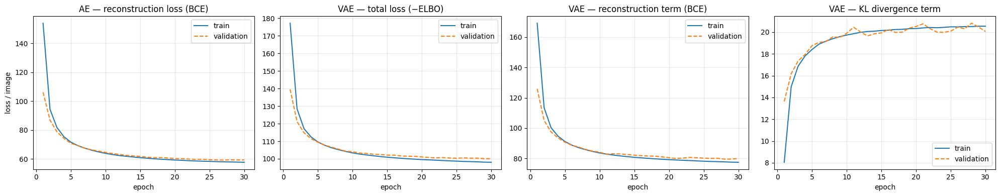

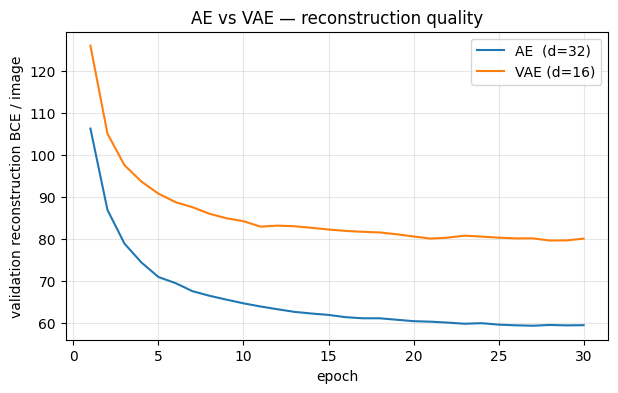

In [9]:
ep = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

axes[0].plot(ep, h_ae["train_total"], label="train"); axes[0].plot(ep, h_ae["val_total"], "--", label="validation")
axes[0].set_title(f"AE — reconstruction loss (BCE)"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss / image"); axes[0].legend()

axes[1].plot(ep, h_vae["train_total"], label="train"); axes[1].plot(ep, h_vae["val_total"], "--", label="validation")
axes[1].set_title("VAE — total loss (−ELBO)"); axes[1].set_xlabel("epoch"); axes[1].legend()

axes[2].plot(ep, h_vae["train_recon"], label="train"); axes[2].plot(ep, h_vae["val_recon"], "--", label="validation")
axes[2].set_title("VAE — reconstruction term (BCE)"); axes[2].set_xlabel("epoch"); axes[2].legend()

axes[3].plot(ep, h_vae["train_kl"], label="train"); axes[3].plot(ep, h_vae["val_kl"], "--", label="validation")
axes[3].set_title("VAE — KL divergence term"); axes[3].set_xlabel("epoch"); axes[3].legend()
plt.tight_layout(); savefig("p1_training_curves"); plt.show()

# Direct comparison of the reconstruction quality (same metric for both models)
plt.figure(figsize=(7, 4))
plt.plot(ep, h_ae["val_recon"],  label=f"AE  (d={AE_CFG['latent_dim']})")
plt.plot(ep, h_vae["val_recon"], label=f"VAE (d={VAE_CFG['latent_dim']})")
plt.xlabel("epoch"); plt.ylabel("validation reconstruction BCE / image"); plt.title("AE vs VAE — reconstruction quality"); plt.legend()
savefig("p1_ae_vs_vae_recon"); plt.show()

### (b) Quantitative comparison on the **test set**
We report the reconstruction BCE, the per-pixel MSE and (for the VAE) the KL term.

In [10]:
@torch.no_grad()
def test_metrics(model, kind):
    r = run_epoch(model, kind, test_loader)
    model.eval(); se, n = 0.0, 0
    for x, _ in test_loader:
        x = x.to(device)
        x_hat = model(x)[0]
        se += F.mse_loss(x_hat, x, reduction="sum").item(); n += x.numel()
    return dict(recon_BCE=r["recon"], KL=r["kl"], total_loss=r["total"], MSE_per_pixel=se / n)

m_ae, m_vae = test_metrics(ae, "ae"), test_metrics(vae, "vae")
comparison = pd.DataFrame({"AE": m_ae, "VAE": m_vae}).T
comparison.insert(0, "latent_dim", [AE_CFG["latent_dim"], VAE_CFG["latent_dim"]])
display(comparison.round(4))
RESULTS["p1_test_metrics"] = {"AE": m_ae, "VAE": m_vae}

,latent_dim,recon_BCE,KL,total_loss,MSE_per_pixel
AE,32,58.7276,0.0000,58.7276,0.0047
VAE,16,78.8613,20.4852,99.3464,0.0128


### (c) Qualitative comparison — reconstructions
First row: original test digits; second row: AE reconstruction; third row: VAE reconstruction.

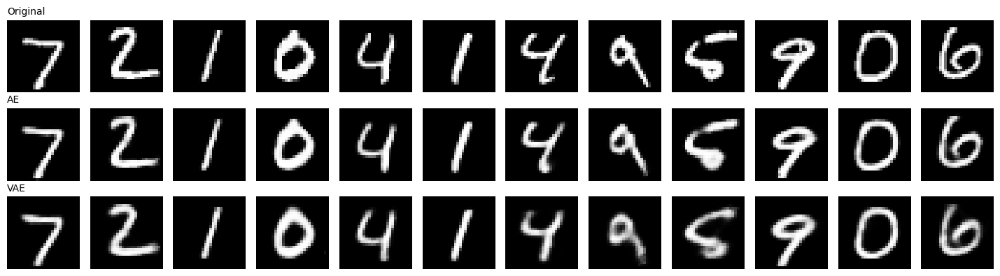

In [11]:
@torch.no_grad()
def show_reconstructions(n=12):
    ae.eval(); vae.eval()
    x, _ = next(iter(test_loader)); x = x[:n].to(device)
    rec_ae  = ae(x)[0]
    vae.eval(); rec_vae = vae.decode(vae.encode(x)[0])     # use the mean mu (deterministic) for display
    rows = [("Original", x), ("AE", rec_ae), ("VAE", rec_vae)]
    fig, axes = plt.subplots(3, n, figsize=(1.2 * n, 4))
    for r, (name, imgs) in enumerate(rows):
        for c in range(n):
            axes[r, c].imshow(imgs[c, 0].cpu(), cmap="gray"); axes[r, c].axis("off")
        axes[r, 0].set_title(name, loc="left", fontsize=10)
    plt.tight_layout(); savefig("p1_reconstructions"); plt.show()
show_reconstructions()

### (d) Generation from the prior — the key difference between AE and VAE
We decode **random points $z\sim\mathcal{N}(0,I)$**. A VAE is trained so that its latent space matches this prior, therefore the samples should look like digits. A plain AE has no constraint on the shape of its latent space, so random codes often fall in "holes" between the clusters.

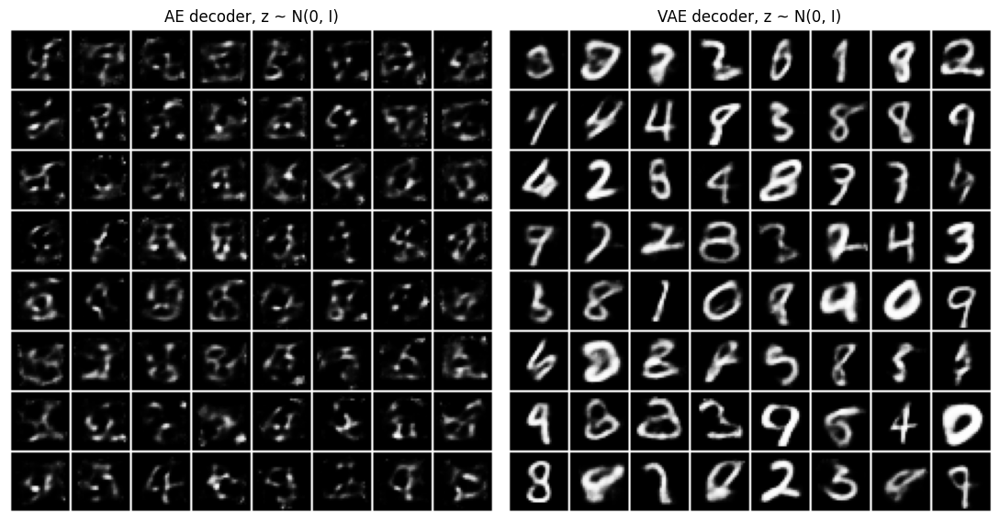

In [12]:
@torch.no_grad()
def sample_prior(model, n=64):
    model.eval()
    z = torch.randn(n, model.latent_dim, device=device)
    return model.decode(z).cpu()

set_seed()
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6))
for ax, (name, m) in zip(axes, [("AE decoder, z ~ N(0, I)", ae), ("VAE decoder, z ~ N(0, I)", vae)]):
    g = make_grid(sample_prior(m), nrow=8, padding=1, pad_value=1)
    ax.imshow(g.permute(1, 2, 0)); ax.set_title(name); ax.axis("off")
plt.tight_layout(); savefig("p1_generation_from_prior"); plt.show()

### (e) Latent-space interpolation
We encode two different digits, move linearly between their codes and decode each step. A smooth, meaningful morphing indicates a well-organised latent space.

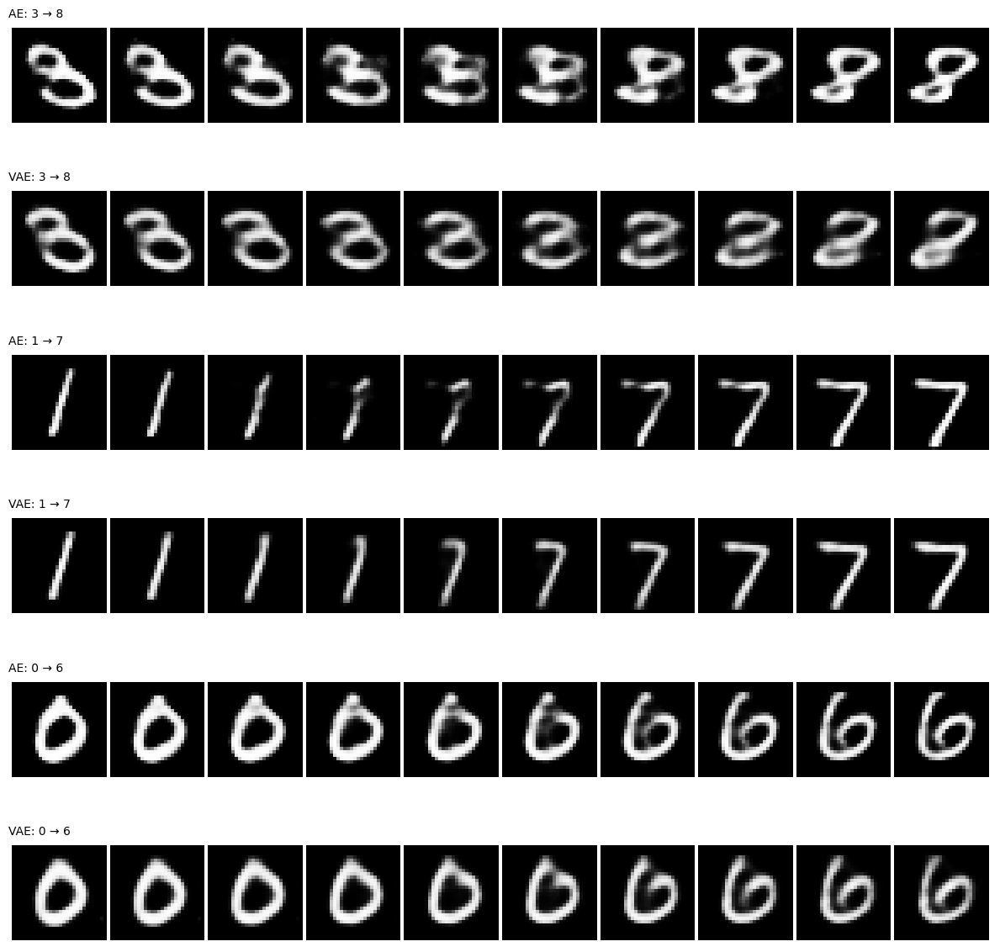

In [13]:
@torch.no_grad()
def interpolate(model, kind, x1, x2, steps=10):
    model.eval()
    enc = (lambda x: model.encoder(x)) if kind == "ae" else (lambda x: model.encode(x)[0])
    z1, z2 = enc(x1), enc(x2)
    alphas = torch.linspace(0, 1, steps, device=device).view(-1, 1)
    z = (1 - alphas) * z1 + alphas * z2
    return model.decode(z).cpu()

xs, ys = next(iter(DataLoader(test_set, batch_size=len(test_set))))
pairs = [(3, 8), (1, 7), (0, 6)]
fig, axes = plt.subplots(len(pairs) * 2, 1, figsize=(12, 2.0 * len(pairs) * 2))
for i, (a, b) in enumerate(pairs):
    x1 = xs[(ys == a).nonzero()[0]].to(device); x2 = xs[(ys == b).nonzero()[0]].to(device)
    for j, (name, m, kind) in enumerate([("AE", ae, "ae"), ("VAE", vae, "vae")]):
        strip = make_grid(interpolate(m, kind, x1, x2), nrow=10, padding=1, pad_value=1)
        ax = axes[2 * i + j]; ax.imshow(strip.permute(1, 2, 0)); ax.axis("off"); ax.set_title(f"{name}: {a} → {b}", loc="left", fontsize=10)
plt.tight_layout(); savefig("p1_interpolation"); plt.show()

### (f) How much information does each latent dimension carry? (VAE)
The average KL divergence per latent dimension shows which dimensions are *active* (KL clearly > 0, they encode information) and which ones have collapsed to the prior ("posterior collapse", KL ≈ 0).

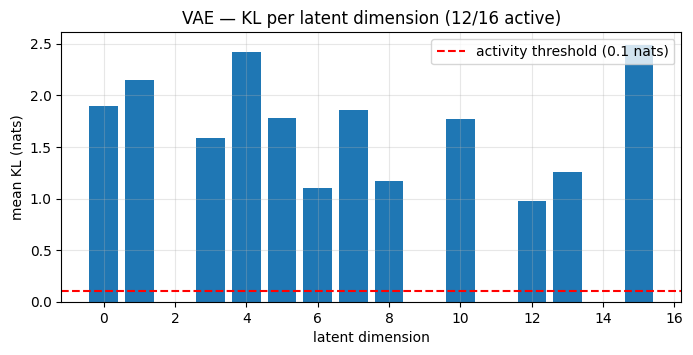

In [14]:
@torch.no_grad()
def kl_per_dim(model):
    model.eval(); tot, n = 0, 0
    for x, _ in test_loader:
        mu, logvar = model.encode(x.to(device))
        tot = tot + (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp())).sum(0); n += x.size(0)
    return (tot / n).cpu().numpy()

kld = kl_per_dim(vae)
n_active = int((kld > 0.1).sum())
plt.figure(figsize=(8, 3.5)); plt.bar(range(len(kld)), kld); plt.axhline(0.1, color="r", ls="--", label="activity threshold (0.1 nats)")
plt.xlabel("latent dimension"); plt.ylabel("mean KL (nats)"); plt.title(f"VAE — KL per latent dimension ({n_active}/{len(kld)} active)"); plt.legend()
savefig("p1_vae_kl_per_dim"); plt.show()
RESULTS["p1_vae_active_dims"] = n_active

## 1.7 Latent-space visualisation
Two complementary views for **each** model:

1. **t-SNE** of the latent codes of the final models (dimension $d$ = best value), 5 000 test digits coloured by class. For the VAE we use the mean $\mu$ of the posterior.
2. **Direct 2-D latent space**: we additionally train a 2-D version of each model (`latent_dim = 2`, same learning rate), so that the latent space can be plotted *without* any dimensionality reduction. We also display the **manifold** obtained by decoding a regular grid of the 2-D latent space.

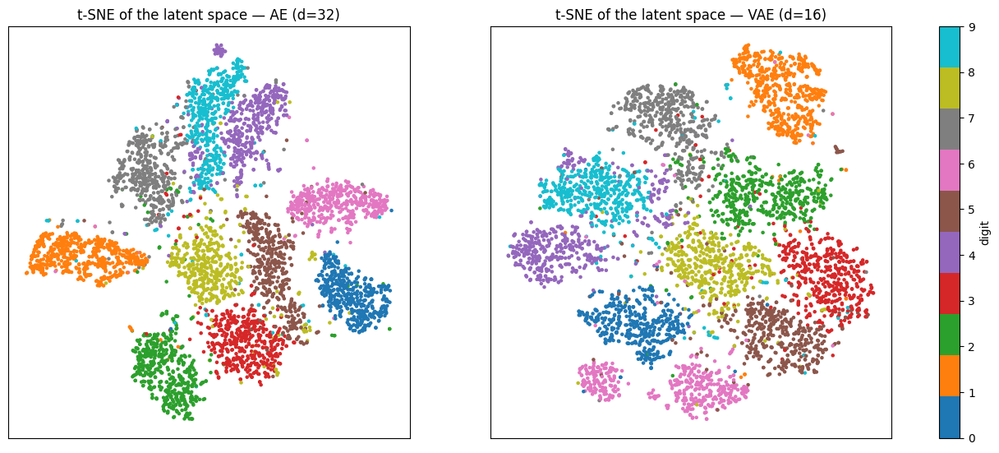

In [15]:
@torch.no_grad()
def get_latents(model, kind, loader):
    model.eval(); zs, ys = [], []
    for x, y in loader:
        x = x.to(device)
        z = model.encoder(x) if kind == "ae" else model.encode(x)[0]
        zs.append(z.cpu()); ys.append(y)
    return torch.cat(zs).numpy(), torch.cat(ys).numpy()

N_TSNE = 5000
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (name, m, kind) in zip(axes, [(f"AE (d={AE_CFG['latent_dim']})", ae, "ae"), (f"VAE (d={VAE_CFG['latent_dim']})", vae, "vae")]):
    z, y = get_latents(m, kind, test_loader)
    z2 = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEED).fit_transform(z[:N_TSNE])
    sc = ax.scatter(z2[:, 0], z2[:, 1], c=y[:N_TSNE], cmap="tab10", s=5)
    ax.set_title(f"t-SNE of the latent space — {name}"); ax.set_xticks([]); ax.set_yticks([])
cbar = fig.colorbar(sc, ax=axes, ticks=range(10), fraction=0.025); cbar.set_label("digit")
savefig("p1_latent_tsne"); plt.show()

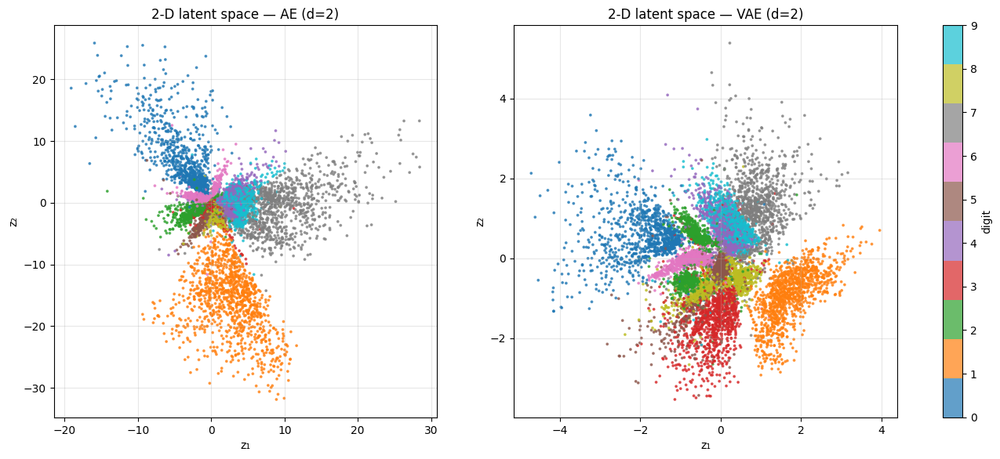

In [16]:
# 2-D latent models (trained only for visualisation purposes)
ae2,  _ = fit("ae",  2, AE_CFG["lr"],  20, verbose=False)
vae2, _ = fit("vae", 2, VAE_CFG["lr"], 20, verbose=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (name, m, kind) in zip(axes, [("AE (d=2)", ae2, "ae"), ("VAE (d=2)", vae2, "vae")]):
    z, y = get_latents(m, kind, test_loader)
    sc = ax.scatter(z[:, 0], z[:, 1], c=y, cmap="tab10", s=3, alpha=0.7)
    ax.set_title(f"2-D latent space — {name}"); ax.set_xlabel("z₁"); ax.set_ylabel("z₂")
cbar = fig.colorbar(sc, ax=axes, ticks=range(10), fraction=0.025); cbar.set_label("digit")
savefig("p1_latent_2d_scatter"); plt.show()

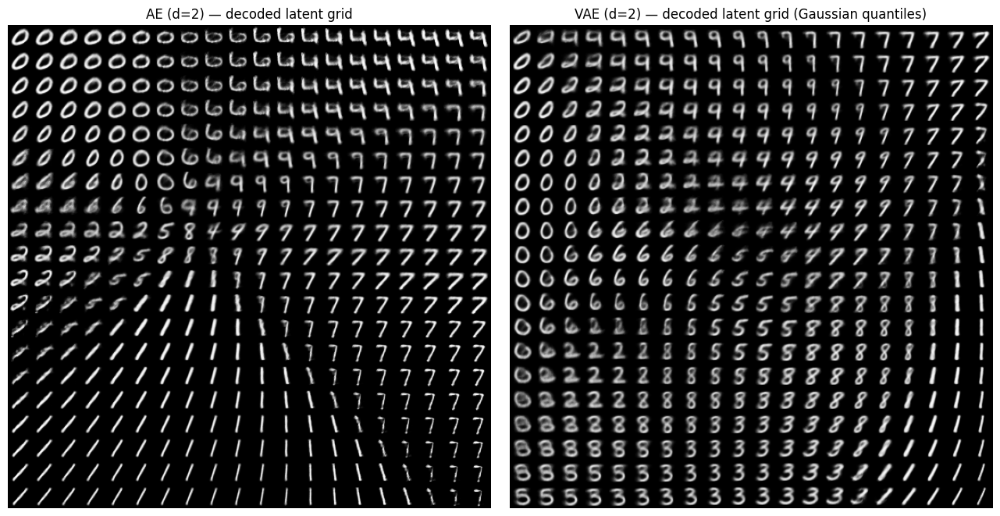

In [17]:
@torch.no_grad()
def manifold(model, z1_vals, z2_vals):
    """Decode a grid of 2-D latent points into one big image (rows: z2 from top to bottom)."""
    model.eval(); n_r, n_c = len(z2_vals), len(z1_vals)
    canvas = np.zeros((n_r * 28, n_c * 28))
    for i, b in enumerate(z2_vals[::-1]):
        zs = torch.tensor([[a, b] for a in z1_vals], dtype=torch.float32, device=device)
        imgs = model.decode(zs).cpu().numpy()[:, 0]
        for j in range(n_c):
            canvas[i * 28:(i + 1) * 28, j * 28:(j + 1) * 28] = imgs[j]
    return canvas

n = 20
# VAE: the prior is N(0, I) -> use quantiles of the Gaussian
q = norm.ppf(np.linspace(0.03, 0.97, n))
# AE: no prior -> cover the range actually used by the encoder (1st-99th percentile)
z_ae, _ = get_latents(ae2, "ae", test_loader)
a1 = np.linspace(*np.percentile(z_ae[:, 0], [1, 99]), n); a2 = np.linspace(*np.percentile(z_ae[:, 1], [1, 99]), n)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
axes[0].imshow(manifold(ae2, a1, a2), cmap="gray");  axes[0].set_title("AE (d=2) — decoded latent grid")
axes[1].imshow(manifold(vae2, q, q), cmap="gray");   axes[1].set_title("VAE (d=2) — decoded latent grid (Gaussian quantiles)")
for ax in axes: ax.axis("off")
plt.tight_layout(); savefig("p1_latent_manifold"); plt.show()

---
# PART 2 — Generative Adversarial Network (GAN) on the Abstract Art Gallery

A GAN is a two-player game between

* a **Generator** $G$ that maps a random noise vector $z\sim\mathcal{N}(0,I)$ to an image $G(z)$, and
* a **Discriminator** $D$ that outputs the probability that an image is real (from the dataset) rather than generated.

$$\min_G\max_D\; \mathbb{E}_{x\sim p_{data}}[\log D(x)] + \mathbb{E}_{z\sim p_z}[\log(1-D(G(z)))]$$

We implement a **DCGAN** (Radford et al., 2016): fully convolutional networks, strided / transposed convolutions instead of pooling, Batch-Norm, ReLU in $G$ and LeakyReLU in $D$, `Tanh` output in $G$.



In [18]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_images(root):
    return sorted(p for p in Path(root).rglob("*") if p.suffix.lower() in IMG_EXT)

def locate_art_dataset():
    candidates = [Path("/kaggle/input/abstract-art-gallery"), Path("abstract-art-gallery"), Path("/content/abstract-art-gallery")]
    kaggle_in = Path("/kaggle/input")
    if kaggle_in.exists():
        candidates += [d for d in kaggle_in.iterdir() if "abstract" in d.name.lower()]
    for c in candidates:
        if c.exists() and len(list_images(c)) > 0:
            return c
    import kagglehub
    return Path(kagglehub.dataset_download("bryanb/abstract-art-gallery"))

DATA_ROOT = locate_art_dataset()
img_paths = list_images(DATA_ROOT)
print("Dataset root :", DATA_ROOT)
print("Images found :", len(img_paths))
assert len(img_paths) > 0, "No image found: check the dataset path."

100%|██████████| 693M/693M [00:11<00:00, 64.2MB/s]

Extracting files...


Dataset root : /root/.cache/kagglehub/datasets/bryanb/abstract-art-gallery/versions/22
Images found : 2872


Loading images:   0%|          | 0/2872 [00:00<?, ?it/s]

2872 images loaded (0 skipped)
Batches per epoch: 44


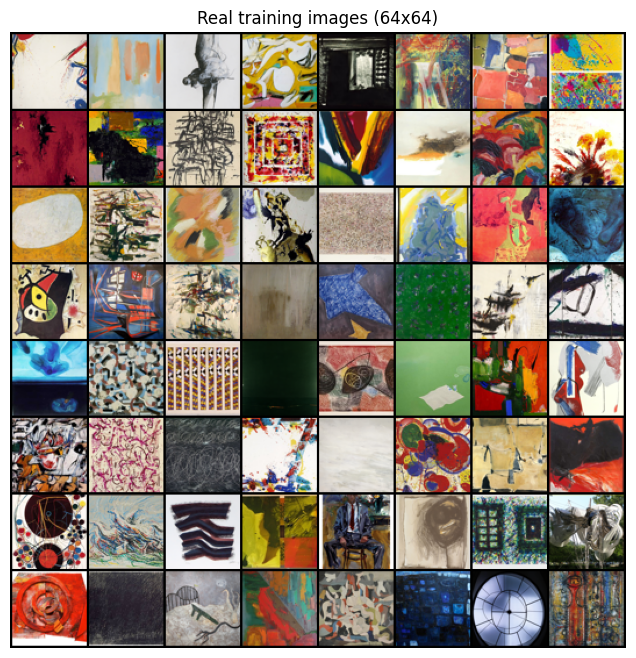

In [19]:
IMG_SIZE, NC = 64, 3

def load_img(path, size=IMG_SIZE):
    """Open -> RGB -> resize shorter side to `size` -> centre-crop `size` x `size`."""
    im = Image.open(path).convert("RGB")
    w, h = im.size; s = size / min(w, h)
    im = im.resize((max(size, round(w * s)), max(size, round(h * s))), Image.Resampling.BICUBIC)
    w, h = im.size; l, t = (w - size) // 2, (h - size) // 2
    return np.asarray(im.crop((l, t, l + size, t + size)))

class ArtDataset(Dataset):
    def __init__(self, paths, size=IMG_SIZE):
        arrs, skipped = [], 0
        for p in tqdm(paths, desc="Loading images"):
            try:
                arrs.append(load_img(p, size))
            except Exception:
                skipped += 1                           # corrupted / unreadable file
        self.data = torch.from_numpy(np.stack(arrs)).permute(0, 3, 1, 2).contiguous()   # uint8, N x 3 x H x W
        print(f"{len(self.data)} images loaded ({skipped} skipped)")
    def __len__(self):
        return len(self.data)
    def __getitem__(self, i):
        x = self.data[i].float() / 127.5 - 1.0         # [-1, 1]
        if random.random() < 0.5:                      # random horizontal flip
            x = torch.flip(x, dims=[2])
        return x
    def all_images(self):                              # un-augmented, for evaluation
        return self.data.float() / 127.5 - 1.0

art_ds = ArtDataset(img_paths)
BATCH_GAN = 64
gan_loader = DataLoader(art_ds, batch_size=BATCH_GAN, shuffle=True, drop_last=True, num_workers=0, pin_memory=(device.type == "cuda"))
print("Batches per epoch:", len(gan_loader))

def show_grid(imgs, title="", nrow=8, ax=None, figsize=(8, 8)):
    """imgs in [-1, 1], shape N x 3 x H x W."""
    g = make_grid(imgs, nrow=nrow, padding=2, normalize=True, value_range=(-1, 1))
    if ax is None: plt.figure(figsize=figsize); ax = plt.gca()
    ax.imshow(g.permute(1, 2, 0).cpu()); ax.set_title(title); ax.axis("off")

set_seed()
show_grid(art_ds.all_images()[torch.randperm(len(art_ds))[:64]], "Real training images (64x64)")
savefig("p2_real_samples"); plt.show()

## 2.2 Hyper-parameters
These values follow the DCGAN recommendations, which are known to give stable training:

| Hyper-parameter | Value | Why |
|---|---|---|
| Image size | 64×64×3 | good trade-off quality / speed for a small dataset |
| Latent dimension `NZ` | 100 | standard DCGAN |
| Feature maps `NGF` / `NDF` | 64 | standard DCGAN |
| Optimiser | Adam, `lr = 2e-4`, `β₁ = 0.5`, `β₂ = 0.999` | low β₁ stabilises adversarial training |
| Batch size | 64 | |
| Epochs | 200 | the dataset is small (≈ 40 iterations / epoch) |
| Real-label smoothing | 0.9 | one-sided label smoothing prevents an over-confident discriminator |
| Weight init | $\mathcal{N}(0, 0.02)$ | DCGAN paper |

In [20]:
NZ, NGF, NDF = 100, 64, 64
LR_GAN, BETA1, BETA2 = 2e-4, 0.5, 0.999
EPOCHS_GAN = 200
REAL_LABEL, FAKE_LABEL = 0.9, 0.0          # one-sided label smoothing

class Generator(nn.Module):
    """z (NZ) -> 4x4 -> 8x8 -> 16x16 -> 32x32 -> 64x64 RGB image in [-1, 1]."""
    def __init__(self, nz=NZ, ngf=NGF, nc=NC):
        super().__init__()
        def up(i, o, k=4, s=2, p=1):
            return [nn.ConvTranspose2d(i, o, k, s, p, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
        self.net = nn.Sequential(
            *up(nz, ngf * 8, 4, 1, 0),             # 1x1   -> 4x4
            *up(ngf * 8, ngf * 4),                 # 4x4   -> 8x8
            *up(ngf * 4, ngf * 2),                 # 8x8   -> 16x16
            *up(ngf * 2, ngf),                     # 16x16 -> 32x32
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False), nn.Tanh(),   # 32x32 -> 64x64
        )
    def forward(self, z):
        return self.net(z.view(z.size(0), -1, 1, 1))

class Discriminator(nn.Module):
    """64x64 image -> one logit (the sigmoid is folded into BCEWithLogitsLoss)."""
    def __init__(self, nc=NC, ndf=NDF):
        super().__init__()
        def down(i, o, bn=True):
            return [nn.Conv2d(i, o, 4, 2, 1, bias=False)] + ([nn.BatchNorm2d(o)] if bn else []) + [nn.LeakyReLU(0.2, True)]
        self.net = nn.Sequential(
            *down(nc, ndf, bn=False),              # 64 -> 32
            *down(ndf, ndf * 2),                   # 32 -> 16
            *down(ndf * 2, ndf * 4),               # 16 -> 8
            *down(ndf * 4, ndf * 8),               # 8  -> 4
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),   # 4 -> 1
        )
    def forward(self, x):
        return self.net(x).view(-1)

def weights_init(m):
    """DCGAN initialisation: N(0, 0.02) for conv layers, N(1, 0.02) for BN scale."""
    name = m.__class__.__name__
    if "Conv" in name:
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif "BatchNorm" in name:
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

# ---- Initialise Generator and Discriminator on the GPU ----
set_seed()
G = Generator().to(device); G.apply(weights_init)
D = Discriminator().to(device); D.apply(weights_init)
print(f"Generator parameters     : {n_params(G):,}")
print(f"Discriminator parameters : {n_params(D):,}")

# ---- Loss function and optimisers ----
criterion = nn.BCEWithLogitsLoss()
optG = torch.optim.Adam(G.parameters(), lr=LR_GAN, betas=(BETA1, BETA2))
optD = torch.optim.Adam(D.parameters(), lr=LR_GAN, betas=(BETA1, BETA2))

# Sanity check of the tensor shapes
with torch.no_grad():
    z = torch.randn(4, NZ, device=device)
    print("G(z) shape:", tuple(G(z).shape), "| D(G(z)) shape:", tuple(D(G(z)).shape))

Generator parameters     : 3,576,704
Discriminator parameters : 2,765,568
G(z) shape: (4, 3, 64, 64) | D(G(z)) shape: (4,)


## 2.3 Training
Each iteration performs:

1. **Discriminator step** — maximise $\log D(x)+\log(1-D(G(z)))$ on a batch of real images (label 0.9) and a batch of fake images (label 0), the fakes being detached from the generator graph.
2. **Generator step** — use the *non-saturating* loss: minimise $-\log D(G(z))$, i.e. train $G$ so that $D$ classifies its fakes as real (label 1).

For diagnosis we log per epoch: $\mathcal{L}_D$, $\mathcal{L}_G$, $D(x)$ (mean score on real images), $D(G(z))$ before the D-update and after it. A fixed noise batch is decoded regularly to visualise the progress of the generator.

In [21]:
fixed_noise = torch.randn(16, NZ, device=device)
SNAP_EPOCHS = sorted({e for e in [1, 5, 10, 25, 50, 100, 150, EPOCHS_GAN] if e <= EPOCHS_GAN})
gan_hist = {"loss_D": [], "loss_G": [], "D_x": [], "D_G_z1": [], "D_G_z2": []}
snapshots = {}

t0 = time.time()
for epoch in range(1, EPOCHS_GAN + 1):
    G.train(); D.train()
    acc = np.zeros(5); n_batches = 0
    for real in gan_loader:
        real = real.to(device, non_blocking=True); b = real.size(0)
        real_lbl = torch.full((b,), REAL_LABEL, device=device)
        fake_lbl = torch.full((b,), FAKE_LABEL, device=device)

        # ---------- (1) Update D ----------
        z = torch.randn(b, NZ, device=device)
        fake = G(z)
        out_real = D(real)
        out_fake = D(fake.detach())
        loss_D = criterion(out_real, real_lbl) + criterion(out_fake, fake_lbl)
        optD.zero_grad(set_to_none=True); loss_D.backward(); optD.step()

        # ---------- (2) Update G (non-saturating loss) ----------
        out_g = D(fake)
        loss_G = criterion(out_g, torch.ones(b, device=device))
        optG.zero_grad(set_to_none=True); loss_G.backward(); optG.step()

        acc += np.array([loss_D.item(), loss_G.item(),
                         torch.sigmoid(out_real).mean().item(),
                         torch.sigmoid(out_fake).mean().item(),
                         torch.sigmoid(out_g).mean().item()])
        n_batches += 1

    for k, v in zip(gan_hist, acc / n_batches):
        gan_hist[k].append(v)

    if epoch in SNAP_EPOCHS:
        G.eval()
        with torch.no_grad(): snapshots[epoch] = G(fixed_noise).cpu()
    if epoch == 1 or epoch % 10 == 0 or epoch == EPOCHS_GAN:
        print(f"Epoch {epoch:3d}/{EPOCHS_GAN} | L_D {gan_hist['loss_D'][-1]:.3f} | L_G {gan_hist['loss_G'][-1]:.3f} | "
              f"D(x) {gan_hist['D_x'][-1]:.3f} | D(G(z)) {gan_hist['D_G_z1'][-1]:.3f} -> {gan_hist['D_G_z2'][-1]:.3f} | "
              f"{(time.time() - t0) / 60:.1f} min")

torch.save(G.state_dict(), OUT / "models" / "generator.pt")
torch.save(D.state_dict(), OUT / "models" / "discriminator.pt")
RESULTS["gan_config"] = dict(img_size=IMG_SIZE, nz=NZ, ngf=NGF, ndf=NDF, lr=LR_GAN, beta1=BETA1, beta2=BETA2, batch_size=BATCH_GAN,
                             epochs=EPOCHS_GAN, real_label=REAL_LABEL, n_train_images=len(art_ds), training_minutes=round((time.time() - t0) / 60, 1))
print("Training finished.")

Epoch   1/200 | L_D 1.038 | L_G 10.447 | D(x) 0.703 | D(G(z)) 0.245 -> 0.001 | 0.1 min
Epoch  10/200 | L_D 0.524 | L_G 5.437 | D(x) 0.825 | D(G(z)) 0.068 -> 0.008 | 0.6 min
Epoch  20/200 | L_D 0.633 | L_G 4.440 | D(x) 0.775 | D(G(z)) 0.127 -> 0.030 | 1.2 min
Epoch  30/200 | L_D 0.673 | L_G 4.833 | D(x) 0.772 | D(G(z)) 0.124 -> 0.025 | 1.8 min
Epoch  40/200 | L_D 0.630 | L_G 4.564 | D(x) 0.771 | D(G(z)) 0.119 -> 0.027 | 2.4 min
Epoch  50/200 | L_D 0.709 | L_G 4.468 | D(x) 0.749 | D(G(z)) 0.146 -> 0.040 | 2.9 min
Epoch  60/200 | L_D 0.743 | L_G 3.618 | D(x) 0.741 | D(G(z)) 0.150 -> 0.073 | 3.5 min
Epoch  70/200 | L_D 0.760 | L_G 3.925 | D(x) 0.738 | D(G(z)) 0.162 -> 0.072 | 4.1 min
Epoch  80/200 | L_D 0.575 | L_G 3.814 | D(x) 0.796 | D(G(z)) 0.111 -> 0.044 | 4.8 min
Epoch  90/200 | L_D 0.570 | L_G 4.076 | D(x) 0.790 | D(G(z)) 0.107 -> 0.039 | 5.4 min
Epoch 100/200 | L_D 0.634 | L_G 3.961 | D(x) 0.781 | D(G(z)) 0.117 -> 0.052 | 6.0 min
Epoch 110/200 | L_D 0.603 | L_G 3.909 | D(x) 0.785 | 

## 2.4 Evaluation of the GAN

### (a) Loss curves of the Generator and the Discriminator


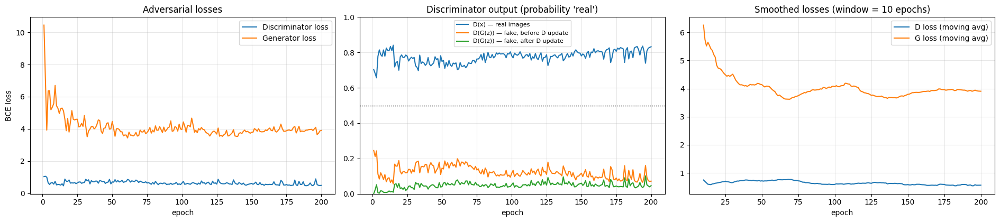

In [22]:
ep = np.arange(1, EPOCHS_GAN + 1)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.3))

axes[0].plot(ep, gan_hist["loss_D"], label="Discriminator loss"); axes[0].plot(ep, gan_hist["loss_G"], label="Generator loss")
axes[0].set_title("Adversarial losses"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("BCE loss"); axes[0].legend()

axes[1].plot(ep, gan_hist["D_x"], label="D(x) — real images")
axes[1].plot(ep, gan_hist["D_G_z1"], label="D(G(z)) — fake, before D update")
axes[1].plot(ep, gan_hist["D_G_z2"], label="D(G(z)) — fake, after D update")
axes[1].axhline(0.5, color="k", ls=":", lw=1); axes[1].set_ylim(0, 1)
axes[1].set_title("Discriminator output (probability 'real')"); axes[1].set_xlabel("epoch"); axes[1].legend(fontsize=8)

k = 10; sm = lambda v: np.convolve(v, np.ones(k) / k, mode="valid")
axes[2].plot(ep[k - 1:], sm(gan_hist["loss_D"]), label="D loss (moving avg)"); axes[2].plot(ep[k - 1:], sm(gan_hist["loss_G"]), label="G loss (moving avg)")
axes[2].set_title(f"Smoothed losses (window = {k} epochs)"); axes[2].set_xlabel("epoch"); axes[2].legend()
plt.tight_layout(); savefig("p2_gan_losses"); plt.show()

### (b) Evolution of the generated images during training
Same fixed noise vectors at several epochs: we observe how the generator goes from noise, to colour blobs, to structured abstract compositions.

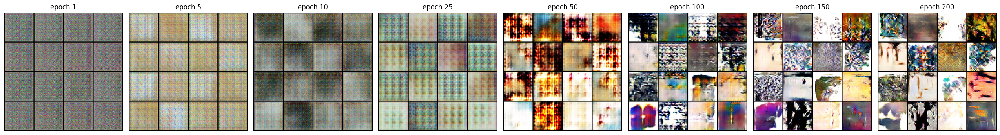

In [23]:
fig, axes = plt.subplots(1, len(snapshots), figsize=(3.2 * len(snapshots), 3.6))
axes = np.atleast_1d(axes)
for ax, (e, imgs) in zip(axes, snapshots.items()):
    show_grid(imgs, f"epoch {e}", nrow=4, ax=ax)
plt.tight_layout(); savefig("p2_training_progress"); plt.show()

## 2.5 Generate new data and compare with the original images

### (a) Visual comparison: real vs. generated

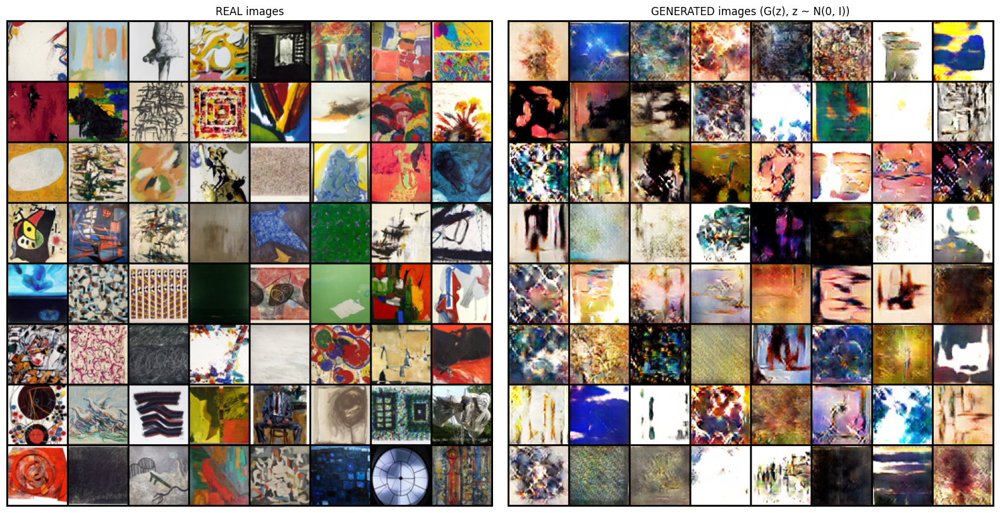

In [24]:
@torch.no_grad()
def generate(n, batch=250):
    G.eval(); out = []
    for i in range(0, n, batch):
        out.append(G(torch.randn(min(batch, n - i), NZ, device=device)).cpu())
    return torch.cat(out)

set_seed()
real_all = art_ds.all_images()
fake_all = generate(len(art_ds))                     # as many generated images as real ones
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
show_grid(real_all[torch.randperm(len(real_all))[:64]], "REAL images", ax=axes[0])
show_grid(fake_all[:64], "GENERATED images (G(z), z ~ N(0, I))", ax=axes[1])
plt.tight_layout(); savefig("p2_real_vs_generated"); plt.show()

### (b) Smooth latent-space interpolation
Walking between two noise vectors shows whether the generator has learned a continuous manifold of paintings (a sign of generalisation rather than memorisation).

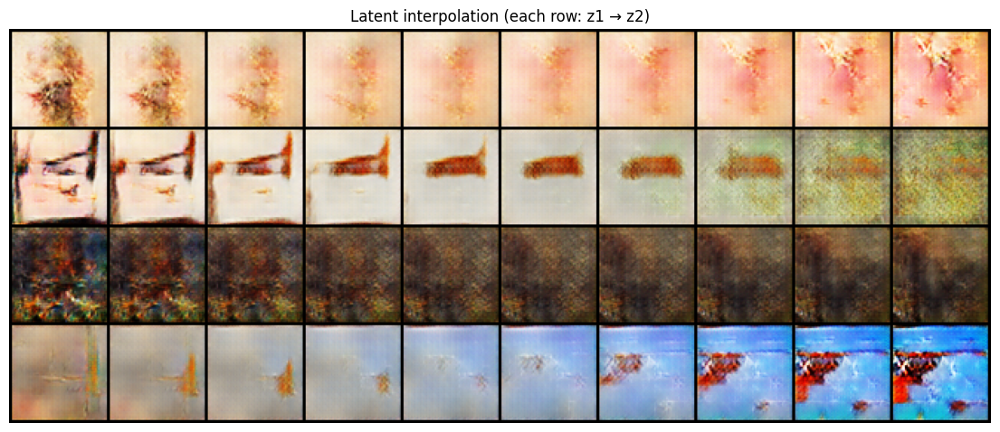

In [25]:
@torch.no_grad()
def latent_interp(n_rows=4, steps=10):
    G.eval(); rows = []
    for _ in range(n_rows):
        z1, z2 = torch.randn(1, NZ, device=device), torch.randn(1, NZ, device=device)
        a = torch.linspace(0, 1, steps, device=device).view(-1, 1)
        rows.append(G((1 - a) * z1 + a * z2).cpu())
    return torch.cat(rows)

set_seed()
show_grid(latent_interp(), "Latent interpolation (each row: z1 → z2)", nrow=10, figsize=(14, 6)); savefig("p2_latent_interpolation"); plt.show()

### (c) Quantitative comparison
**1. Pixel statistics** — mean / standard deviation of each colour channel and the global intensity histogram, for real vs. generated images.

,real_mean,generated_mean,real_std,generated_std
R,0.5801,0.5993,0.2873,0.3242
G,0.5241,0.5393,0.2726,0.3096
B,0.4734,0.4991,0.2752,0.3131


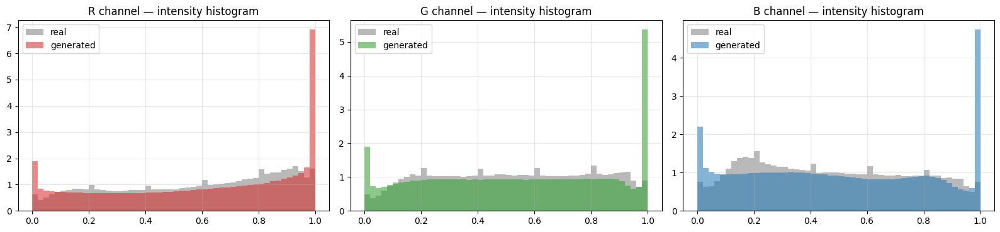

In [26]:
def channel_stats(x):
    x01 = (x + 1) / 2
    return x01.mean((0, 2, 3)).numpy(), x01.std((0, 2, 3)).numpy()

mr, sr = channel_stats(real_all); mf, sf = channel_stats(fake_all)
stats_df = pd.DataFrame({"real_mean": mr, "generated_mean": mf, "real_std": sr, "generated_std": sf}, index=["R", "G", "B"])
display(stats_df.round(4))
RESULTS["p2_pixel_stats"] = stats_df.round(4).to_dict()

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for c, (name, col) in enumerate(zip("RGB", ["tab:red", "tab:green", "tab:blue"])):
    axes[c].hist(((real_all[:, c] + 1) / 2).flatten().numpy(), bins=50, alpha=0.55, density=True, label="real", color="gray")
    axes[c].hist(((fake_all[:, c] + 1) / 2).flatten().numpy(), bins=50, alpha=0.55, density=True, label="generated", color=col)
    axes[c].set_title(f"{name} channel — intensity histogram"); axes[c].legend()
plt.tight_layout(); savefig("p2_pixel_histograms"); plt.show()

**2. Fréchet Inception Distance (FID)** — distance between the Gaussian fitted to the Inception-v3 features of the real images and the one fitted to the generated images ($\text{lower} = \text{better}$):

$$FID=\lVert\mu_r-\mu_g\rVert^2+\mathrm{Tr}\!\left(\Sigma_r+\Sigma_g-2(\Sigma_r\Sigma_g)^{1/2}\right)$$

Since the dataset is small, the absolute value of FID is biased; to give it a scale we also report the **real-vs-real baseline** (FID between two random halves of the real data, the best value one can hope for) and the FID of **pure noise images** (a worst-case reference).

In [27]:
from scipy import linalg
from torchvision.models import inception_v3, Inception_V3_Weights

def frechet_distance(f1, f2, eps=1e-6):
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean = linalg.sqrtm(s1.dot(s2))
    if not np.isfinite(covmean).all():
        off = np.eye(s1.shape[0]) * eps
        covmean = linalg.sqrtm((s1 + off).dot(s2 + off))
    covmean = covmean.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))

try:
    inception = inception_v3(weights=Inception_V3_Weights.IMAGENET1K_V1).to(device).eval()
    inception.fc = nn.Identity()                                   # 2048-d pooled features
    im_mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    im_std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

    @torch.no_grad()
    def inception_features(x, bs=100):
        feats = []
        for i in range(0, len(x), bs):
            b = (x[i:i + bs].to(device) + 1) / 2
            b = F.interpolate(b, size=(299, 299), mode="bilinear", align_corners=False)
            feats.append(inception((b - im_mean) / im_std).cpu())
        return torch.cat(feats).numpy().astype(np.float64)

    set_seed()
    f_real = inception_features(real_all)
    f_fake = inception_features(fake_all)
    f_noise = inception_features(torch.rand_like(real_all[:1000]) * 2 - 1)
    perm = np.random.permutation(len(f_real)); h = len(perm) // 2

    fid_gen   = frechet_distance(f_real, f_fake)
    fid_base  = frechet_distance(f_real[perm[:h]], f_real[perm[h:]])
    fid_noise = frechet_distance(f_real, f_noise)
    print(f"FID real vs generated        : {fid_gen:8.2f}")
    print(f"FID real vs real (baseline)  : {fid_base:8.2f}   <- lower bound")
    print(f"FID real vs random noise     : {fid_noise:8.2f}   <- worst-case reference")
    RESULTS["p2_fid"] = dict(generated=fid_gen, real_vs_real_baseline=fid_base, noise=fid_noise)
except Exception as e:
    print("FID could not be computed (", type(e).__name__, ":", e, ")\nCheck that the Internet is enabled (the Inception weights are downloaded).")

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 160MB/s] 


FID real vs generated        :    81.59
FID real vs real (baseline)  :    41.89   <- lower bound
FID real vs random noise     :   314.52   <- worst-case reference


**3. Memorisation check** — a GAN trained on a small dataset might simply copy training images. For 8 generated images we display the *nearest real image* (L2 distance in pixel space). If the pairs are clearly different, the generator creates new compositions.

In [ ]:
@torch.no_grad()
def nearest_real(fakes, reals):
    d = torch.cdist(fakes.flatten(1).to(device), reals.flatten(1).to(device))
    return d.argmin(1).cpu(), d.min(1).values.cpu()

idx, dist = nearest_real(fake_all[:8], real_all)
pairs = torch.cat([fake_all[:8], real_all[idx]])
show_grid(pairs, "Top row: generated  |  Bottom row: nearest real image (L2)", nrow=8, figsize=(14, 4)); savefig("p2_nearest_neighbours"); plt.show()
print("L2 distances to the nearest real image:", np.round(dist.numpy(), 1))

---
# Export of the results
All the numbers collected during the run are saved in `outputs/results.json`, and the whole `outputs/` folder is zipped (figures, weights, results) to be pushed to my repository.

In [29]:
def to_py(o):
    if isinstance(o, dict):  return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o

RESULTS["device"] = torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"
RESULTS["gan_final_epoch"] = {k: round(v[-1], 4) for k, v in gan_hist.items()}
with open(OUT / "results.json", "w") as f:
    json.dump(to_py(RESULTS), f, indent=2)
shutil.make_archive("lab4_outputs", "zip", "outputs")
print(json.dumps(to_py({k: v for k, v in RESULTS.items() if k not in ("ae_grid", "vae_grid")}), indent=2))
print("\nSaved: outputs/results.json and lab4_outputs.zip")

{
  "ae_config": {
    "latent_dim": 32,
    "lr": 0.001,
    "epochs": 30,
    "batch_size": 128,
    "optimizer": "Adam",
    "best_epoch": 27
  },
  "vae_config": {
    "latent_dim": 16,
    "lr": 0.001,
    "epochs": 30,
    "batch_size": 128,
    "optimizer": "Adam",
    "beta": 1.0,
    "best_epoch": 29
  },
  "p1_test_metrics": {
    "AE": {
      "recon_BCE": 58.72759158325195,
      "KL": 0.0,
      "total_loss": 58.72759158325195,
      "MSE_per_pixel": 0.004654677298604226
    },
    "VAE": {
      "recon_BCE": 78.86125627441406,
      "KL": 20.485156622314452,
      "total_loss": 99.34641296386718,
      "MSE_per_pixel": 0.01281857372400712
    }
  },
  "p1_vae_active_dims": 12,
  "gan_config": {
    "img_size": 64,
    "nz": 100,
    "ngf": 64,
    "ndf": 64,
    "lr": 0.0002,
    "beta1": 0.5,
    "beta2": 0.999,
    "batch_size": 64,
    "epochs": 200,
    "real_label": 0.9,
    "n_train_images": 2872,
    "training_minutes": 12.2
  },
  "p2_pixel_stats": {
    "real_mea